# Explaining a 1D-CNN ECG Heartbeat Classifier: Six XAI Methods, Beat Geometry, and a Padding Shortcut

**Dataset:** Kaggle *ECG Heartbeat Categorization* (MIT-BIH part, Kachuee et al., 2018): `mitbih_train.csv` (87,554 beats) and `mitbih_test.csv` (21,892 beats), 187 samples at 125 Hz, 5 AAMI classes (N, S, V, F, Q).

**What this notebook does:**
1. **Geometry audit.** Checks where the R-peak and zero-padding actually sit in each beat window. Fixed-centre wave windows assume the R-peak is at the centre; this checks that assumption.
2. **Simple CNN.** Trains the Kachuee residual 1D-CNN with class-weighted loss and evaluates it on the official test split.
3. **Six XAI methods, step by step.** Gradient Saliency, Integrated Gradients, Grad-CAM, Occlusion (perturbation saliency), Kernel SHAP and LIME, each shown on one beat per class to explain *how the model classified it*.
4. **Geometry-Aware Region Aggregation (GARA).** Maps point-wise attributions to QRS / ST-T / TP(P) / next-QRS / padding, using each beat's *own* RR geometry.
5. **Quantitative comparison.** Faithfulness (ROAD-style MoRF/LeRF with linear imputation), a sanity check (model randomisation), agreement between methods (Krishna et al.), and plausibility (region shares, QRS-focus).
6. **Novel analysis: padding-shortcut audit.** Measures attribution on the zero-padding boundary, runs a counterfactual intervention that removes the padding step, and retrains a padding-invariant model as a mitigation.

Run on Kaggle (GPU optional): *Add Data → "ECG Heartbeat Categorization Dataset" (shayanfazeli/heartbeat)*. Total runtime is about 25 min on 2 CPU cores and a few minutes on a GPU.

In [111]:
# while True:
#     pass

In [112]:
# ---------- 0. Setup ----------
import subprocess, sys, os, glob, json, time, copy, random, warnings
def _ensure(pkg, imp=None):
    try:
        __import__(imp or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
for _p in ["captum", "seaborn"]:
    _ensure(_p)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.stats import spearmanr, pearsonr
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix, f1_score,
                             accuracy_score, balanced_accuracy_score, recall_score)
from captum.attr import Saliency, IntegratedGradients, LayerGradCam, Occlusion, KernelShap, Lime
from captum._utils.models.linear_model import SkLearnRidge
warnings.filterwarnings("ignore")

SMOKE = os.environ.get("SMOKE", "0") == "1"       # quick debug run
SEED = 45 # 42,43 is done 
EPOCHS, PATIENCE, BATCH, LR = (1, 1, 512, 1e-3) if SMOKE else (50, 8, 256, 1e-3)
N_PER_CLASS = 6 if SMOKE else 100     # correctly classified test beats per class for XAI evaluation
N_SANITY = 10 if SMOKE else 150       # beats used for the randomisation sanity check
SEG_W = 6                             # feature width for Occlusion/SHAP/LIME: 6 samples = 48 ms
SHAP_SAMPLES = LIME_SAMPLES = 60 if SMOKE else 200
IG_STEPS = 32
FS, N_T = 125, 187
CLASSES = ["N", "S", "V", "F", "Q"]
CLASS_NAMES = {"N": "Normal", "S": "Supraventricular", "V": "Ventricular", "F": "Fusion", "Q": "Unknown/Paced"}
METHODS = ["saliency", "ig", "gradcam", "occlusion", "kernelshap", "lime"]
MNAME = {"saliency": "Gradient Saliency", "ig": "Integrated Gradients", "gradcam": "Grad-CAM",
         "occlusion": "Occlusion", "kernelshap": "Kernel SHAP", "lime": "LIME", "random": "Random"}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = f"outputs_seed{SEED}"; os.makedirs(OUT, exist_ok=True)
trapz = getattr(np, "trapezoid", None) or np.trapz

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
seed_all()
if DEVICE.type == "cpu": torch.set_num_threads(max(1, os.cpu_count() or 1))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
def savefig(name): plt.savefig(os.path.join(OUT, name), dpi=150, bbox_inches="tight")
print("device:", DEVICE, "| smoke:", SMOKE)

device: cuda | smoke: False


## 1. Data

In [113]:
def locate_data():
    for pat in ["/kaggle/input/**/mitbih_train.csv", "data/mitbih_train.csv", "../data/mitbih_train.csv", "mitbih_train.csv"]:
        hits = glob.glob(pat, recursive=True)
        if hits: return os.path.dirname(hits[0])
    import kagglehub                     # fallback: needs internet
    return kagglehub.dataset_download("shayanfazeli/heartbeat")

DATA = locate_data(); print("data dir:", DATA)
tr = pd.read_csv(os.path.join(DATA, "mitbih_train.csv"), header=None).values.astype(np.float32)
te = pd.read_csv(os.path.join(DATA, "mitbih_test.csv"), header=None).values.astype(np.float32)
X_full, y_full = tr[:, :-1], tr[:, -1].astype(int)
X_te, y_te = te[:, :-1], te[:, -1].astype(int)
print("train", X_full.shape, np.bincount(y_full), "| test", X_te.shape, np.bincount(y_te))

data dir: /kaggle/input/datasets/shayanfazeli/heartbeat
train (87554, 187) [72471  2223  5788   641  6431] | test (21892, 187) [18118   556  1448   162  1608]


## 2. Geometry audit: where are the R-peak and the padding?

Kachuee et al.'s preprocessing finds R-peaks in 10 s windows and sets **T = median RR** of that window. For each R-peak it **starts the segment at the R-peak** and takes **1.2·T** samples, then zero-pads to 187. So:
- the labelled beat's **R-peak is at index 0**, not at the centre;
- its own **P-wave and preceding RR interval are *not* in the window**;
- the window ends around the **next** beat's QRS (≈ T), followed by **zero padding** from L = 1.2·T to 187;
- the padding start L encodes the 10 s **window-median heart rate**, a recording-level quantity rather than a property of the beat's own morphology.

The cell below checks this empirically. If true, any wave-region scheme that places the QRS at the window centre (index ≈ 93) is measuring the wrong place.

{
 "frac_x0_gt_0.9": 0.7884048701372867,
 "median_argmax_index": 28.0,
 "median_L": 109.0,
 "median_T_ms": 726.6666666666667,
 "frac_centre_idx93_is_padding": 0.24235329054069488,
 "median_L_by_class": {
  "N": 106.0,
  "S": 107.0,
  "V": 114.0,
  "F": 78.0,
  "Q": 120.0
 }
}


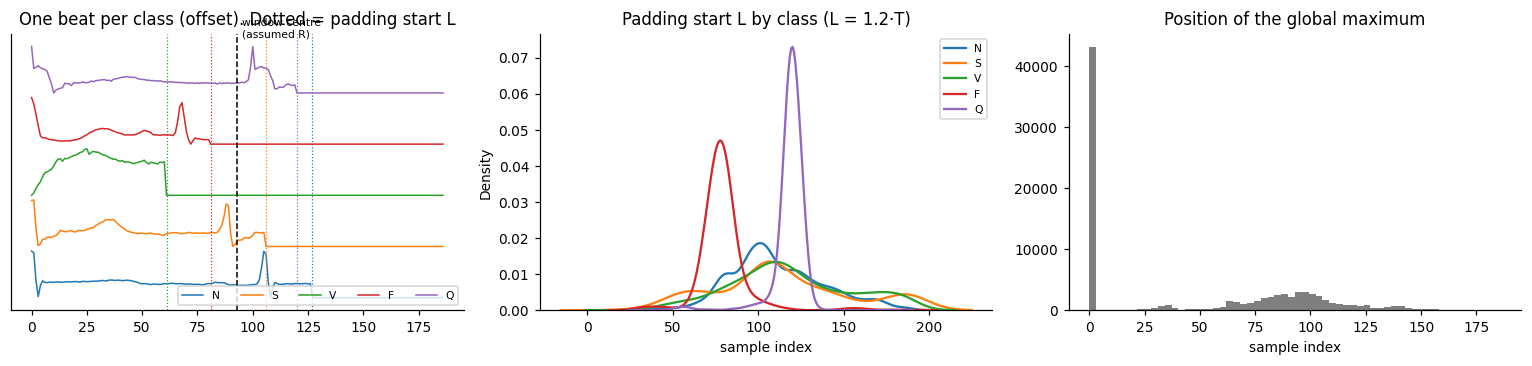

In [114]:
def effective_length(X):
    """L = index after the last non-zero sample (start of trailing zero padding)."""
    nz = X != 0
    L = X.shape[1] - np.argmax(nz[:, ::-1], axis=1)
    L[~nz.any(1)] = 0
    return L

L_full, L_te = effective_length(X_full), effective_length(X_te)
geo = {
    "frac_x0_gt_0.9": float((X_full[:, 0] > 0.9).mean()),
    "median_argmax_index": float(np.median(X_full.argmax(1))),
    "median_L": float(np.median(L_full)),
    "median_T_ms": float(np.median(L_full / 1.2) / FS * 1000),
    "frac_centre_idx93_is_padding": float((np.arange(N_T)[93] >= L_full).mean()),
    "median_L_by_class": {c: float(np.median(L_full[y_full == i])) for i, c in enumerate(CLASSES)},
}
print(json.dumps(geo, indent=1))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
rng = np.random.default_rng(1)
for i, c in enumerate(CLASSES):
    j = rng.choice(np.where(y_full == i)[0])
    ax[0].plot(X_full[j] + i * 1.1, lw=1, label=c)
    ax[0].axvline(L_full[j], ymin=0, ymax=1, color=f"C{i}", ls=":", lw=0.8)
ax[0].axvline(93, color="k", ls="--", lw=1); ax[0].text(95, 5.6, "window centre\n(assumed R)", fontsize=7)
ax[0].set_title("One beat per class (offset). Dotted = padding start L"); ax[0].set_yticks([]); ax[0].legend(fontsize=7, ncol=5, loc="lower right")
for i, c in enumerate(CLASSES):
    sns.kdeplot(L_full[y_full == i], ax=ax[1], label=c, bw_adjust=1.5)
ax[1].set_title("Padding start L by class (L = 1.2·T)"); ax[1].set_xlabel("sample index"); ax[1].legend(fontsize=7)
ax[2].hist(X_full.argmax(1), bins=60, color="C7"); ax[2].set_title("Position of the global maximum"); ax[2].set_xlabel("sample index")
plt.tight_layout(); savefig("fig01_geometry_audit.png"); plt.show()

### 2.1 How much does the padding start alone reveal? (shortcut potential)
If a model given **only L** (one scalar, no morphology) beats chance by a wide margin, the padding boundary is a usable shortcut for a CNN.

In [115]:
gb = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED).fit(L_full[:, None], y_full)
p_len = gb.predict(L_te[:, None])
len_only = {"acc": accuracy_score(y_te, p_len), "balanced_acc": balanced_accuracy_score(y_te, p_len),
            "macro_f1": f1_score(y_te, p_len, average="macro"), "chance_balanced_acc": 0.2}
print("Length-only classifier:", {k: round(v, 3) for k, v in len_only.items()})
print("per-class recall:", dict(zip(CLASSES, np.round(recall_score(y_te, p_len, average=None), 3))))

Length-only classifier: {'acc': 0.394, 'balanced_acc': np.float64(0.58), 'macro_f1': 0.263, 'chance_balanced_acc': 0.2}
per-class recall: {'N': np.float64(0.356), 'S': np.float64(0.55), 'V': np.float64(0.209), 'F': np.float64(0.895), 'Q': np.float64(0.891)}


### 2.2 Geometry-Aware Region Aggregation (GARA) vs. fixed-centre windows
Per beat, with $T = L/1.2$ (R-peak at index 0, next R at ≈T):

| Region | Window | Physiology |
|---|---|---|
| **QRS** | $[0,\ \max(6, 0.12T))$ | R down-stroke + S of the labelled beat (≥48 ms) |
| **ST-T** | $[0.12T,\ 0.55T)$ | repolarisation of the labelled beat |
| **TP / P(next)** | $[0.55T,\ 0.92T)$ | diastole + P-wave of the *next* beat |
| **QRS(next)** | $[0.92T,\ L)$ | next beat's QRS. Its position encodes the following RR interval |
| **PAD** | $[L,\ 187)$ | zero padding (non-physiological) |

The **fixed-centre** scheme puts R at index 93 with P = [−0.2T, −0.08T), QRS = ±0.08T and T-wave = [0.1T, 0.4T], using one nominal T for all beats.

Fraction of each fixed-centre window that actually falls in each GARA region (test set):
            QRS   ST-T  TP/P(next)  QRS(next)    PAD
P(fixed)    0.0  0.023       0.538      0.319  0.120
QRS(fixed)  0.0  0.000       0.321      0.423  0.255
T(fixed)    0.0  0.000       0.101      0.308  0.591


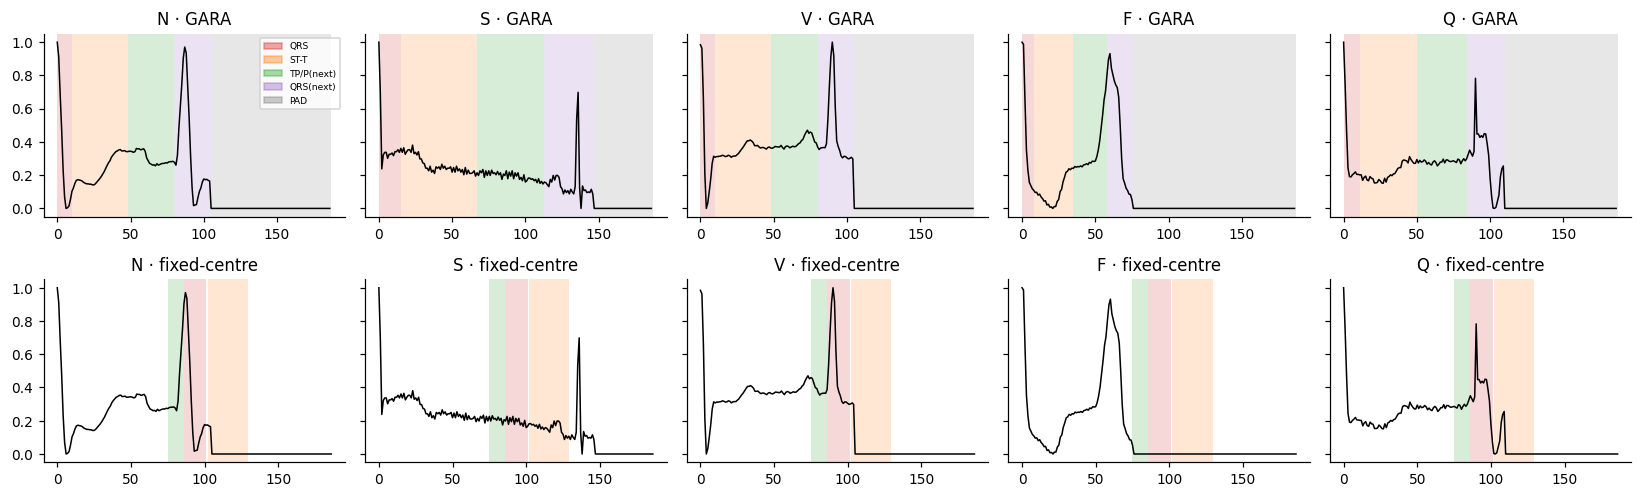

In [116]:
REGIONS = ["QRS", "ST-T", "TP/P(next)", "QRS(next)", "PAD"]
def gara_masks(L, n=N_T):
    L = np.asarray(L); T = L / 1.2; idx = np.arange(n)[None, :]
    q = np.maximum(6, np.round(0.12 * T)).astype(int)[:, None]
    s = np.maximum(q[:, 0] + 1, np.round(0.55 * T)).astype(int)[:, None]
    p = np.maximum(s[:, 0] + 1, np.round(0.92 * T)).astype(int)[:, None]
    Lc = np.maximum(p[:, 0], L)[:, None]
    m = np.zeros((len(L), 5, n), bool)
    m[:, 0] = idx < q; m[:, 1] = (idx >= q) & (idx < s); m[:, 2] = (idx >= s) & (idx < p)
    m[:, 3] = (idx >= p) & (idx < Lc); m[:, 4] = idx >= Lc
    return m

T_NOM = float(np.median(L_full / 1.2)); C0 = 93
FIXED = {"P(fixed)": (C0 - 0.2 * T_NOM, C0 - 0.08 * T_NOM), "QRS(fixed)": (C0 - 0.08 * T_NOM, C0 + 0.08 * T_NOM + 1),
         "T(fixed)": (C0 + 0.1 * T_NOM, C0 + 0.4 * T_NOM)}
def fixed_masks(n_beats, n=N_T):
    idx = np.arange(n); m = np.zeros((n_beats, len(FIXED), n), bool)
    for k, (a, b) in enumerate(FIXED.values()): m[:, k] = (idx >= int(round(a))) & (idx < int(round(b)))
    return m

G_te = gara_masks(L_te); Fm_te = fixed_masks(len(L_te))
mis = np.array([[(Fm_te[:, k] & G_te[:, r]).sum(1).mean() / Fm_te[0, k].sum() for r in range(5)] for k in range(len(FIXED))])
mis_df = pd.DataFrame(mis, index=list(FIXED), columns=REGIONS).round(3)
print("Fraction of each fixed-centre window that actually falls in each GARA region (test set):"); print(mis_df)

fig, ax = plt.subplots(2, 5, figsize=(15, 4.6), sharey=True)
reg_col = ["#d62728", "#ff7f0e", "#2ca02c", "#9467bd", "#7f7f7f"]
for i, c in enumerate(CLASSES):
    j = np.where(y_te == i)[0][3]; g = gara_masks(L_te[[j]])[0]
    for r in range(5):
        xs = np.where(g[r])[0]
        if len(xs): ax[0, i].axvspan(xs[0], xs[-1] + 1, color=reg_col[r], alpha=0.18, lw=0)
    ax[0, i].plot(X_te[j], "k", lw=1); ax[0, i].set_title(f"{c} · GARA")
    for k, (a, b) in enumerate(FIXED.values()): ax[1, i].axvspan(a, b, color=["#2ca02c", "#d62728", "#ff7f0e"][k], alpha=0.18, lw=0)
    ax[1, i].plot(X_te[j], "k", lw=1); ax[1, i].set_title(f"{c} · fixed-centre")
ax[0, 0].legend(handles=[mpatches.Patch(color=reg_col[r], alpha=.4, label=REGIONS[r]) for r in range(5)], fontsize=6, loc="upper right")
plt.tight_layout(); savefig("fig02_gara_vs_fixed.png"); plt.show()

## 3. Model: Kachuee residual 1D-CNN
Five residual blocks (Conv1d 32@5 → ReLU → Conv1d 32@5 → +skip → ReLU → MaxPool 5/2), then FC 32 → 32 → 5. Imbalance is handled with a **square-root inverse-frequency class-weighted cross-entropy**, which is simple and introduces no synthetic beats and no leakage risk. Validation is a stratified 10 % of the training CSV; the **official `mitbih_test.csv`** is used only for testing.

In [117]:
class ResBlock(nn.Module):
    def __init__(s, c=32, k=5):
        super().__init__()
        s.c1 = nn.Conv1d(c, c, k, padding=k // 2); s.a1 = nn.ReLU()
        s.c2 = nn.Conv1d(c, c, k, padding=k // 2); s.a2 = nn.ReLU()   # a2 = Grad-CAM target in last block
        s.pool = nn.MaxPool1d(5, 2)
    def forward(s, x): return s.pool(s.a2(s.c2(s.a1(s.c1(x))) + x))

class KachueeCNN(nn.Module):
    def __init__(s, n_cls=5):
        super().__init__()
        s.stem = nn.Conv1d(1, 32, 5, padding=2)
        s.blocks = nn.Sequential(*[ResBlock() for _ in range(5)])        # 187→92→44→20→8→2
        s.head = nn.Sequential(nn.Flatten(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 32), nn.ReLU(), nn.Linear(32, n_cls))
    def forward(s, x): return s.head(s.blocks(s.stem(x)))

X_tr, X_va, y_tr, y_va = train_test_split(X_full, y_full, test_size=0.1, stratify=y_full, random_state=SEED)
L_tr = effective_length(X_tr)
cnt = np.bincount(y_tr); CW = torch.tensor((cnt.max() / cnt) ** 0.5, dtype=torch.float32)
print("class weights:", dict(zip(CLASSES, CW.numpy().round(2))), "| params:", sum(p.numel() for p in KachueeCNN().parameters()))

@torch.no_grad()
def predict_proba(model, X, bs=4096):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        out.append(F.softmax(model(torch.from_numpy(np.ascontiguousarray(X[i:i + bs])).float().unsqueeze(1).to(DEVICE)), 1).cpu().numpy())
    return np.concatenate(out)

def augment_padding(xb, Lb):
    """Padding-invariance augmentation: per beat keep zeros, fill padding with the edge value, or edge + noise."""
    B = xb.shape[0]; idx = torch.arange(xb.shape[-1], device=xb.device)
    m = idx[None, :] >= Lb[:, None]
    edge = xb[torch.arange(B, device=xb.device), 0, (Lb - 1).clamp(min=0)]
    mode = torch.randint(0, 3, (B,), device=xb.device)
    fill = edge[:, None] + (mode == 2).float()[:, None] * 0.01 * torch.randn(B, xb.shape[-1], device=xb.device)
    return torch.where((mode > 0)[:, None] & m, fill, xb[:, 0]).unsqueeze(1)

def train_model(augment=False, tag="A"):
    seed_all(); model = KachueeCNN().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    Xt = torch.from_numpy(X_tr).unsqueeze(1); yt = torch.from_numpy(y_tr); Lt = torch.from_numpy(L_tr)
    best, best_state, bad, hist = -1, None, 0, []
    for ep in range(EPOCHS):
        model.train(); perm = torch.randperm(len(Xt)); t0 = time.time(); tot = 0
        for i in range(0, len(Xt), BATCH):
            b = perm[i:i + BATCH]; xb, yb = Xt[b].to(DEVICE), yt[b].to(DEVICE)
            if augment: xb = augment_padding(xb, Lt[b].to(DEVICE))
            loss = F.cross_entropy(model(xb), yb, weight=CW.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        pv = predict_proba(model, X_va).argmax(1); f1 = f1_score(y_va, pv, average="macro"); sched.step(f1)
        hist.append({"epoch": ep + 1, "loss": tot / len(Xt), "val_macro_f1": f1, "val_acc": accuracy_score(y_va, pv)})
        print(f"[{tag}] ep {ep+1:2d} loss {tot/len(Xt):.4f} val-acc {hist[-1]['val_acc']:.4f} val-macroF1 {f1:.4f} ({time.time()-t0:.0f}s)")
        if f1 > best: best, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    model.load_state_dict(best_state); torch.save(best_state, os.path.join(OUT, f"model_{tag}.pt"))
    return model.eval(), pd.DataFrame(hist)

model_A, hist_A = train_model(augment=False, tag="A")

class weights: {'N': np.float32(1.0), 'S': np.float32(5.71), 'V': np.float32(3.54), 'F': np.float32(10.63), 'Q': np.float32(3.36)} | params: 55013
[A] ep  1 loss 0.8069 val-acc 0.9073 val-macroF1 0.6094 (3s)
[A] ep  2 loss 0.3716 val-acc 0.9541 val-macroF1 0.8058 (2s)
[A] ep  3 loss 0.2645 val-acc 0.9614 val-macroF1 0.8239 (3s)
[A] ep  4 loss 0.2290 val-acc 0.9349 val-macroF1 0.7605 (3s)
[A] ep  5 loss 0.2016 val-acc 0.9627 val-macroF1 0.8386 (2s)
[A] ep  6 loss 0.1826 val-acc 0.9685 val-macroF1 0.8532 (2s)
[A] ep  7 loss 0.1601 val-acc 0.9685 val-macroF1 0.8689 (2s)
[A] ep  8 loss 0.1490 val-acc 0.9757 val-macroF1 0.8830 (2s)
[A] ep  9 loss 0.1361 val-acc 0.9793 val-macroF1 0.8912 (3s)
[A] ep 10 loss 0.1271 val-acc 0.9749 val-macroF1 0.8761 (2s)
[A] ep 11 loss 0.1231 val-acc 0.9777 val-macroF1 0.8787 (2s)
[A] ep 12 loss 0.1111 val-acc 0.9762 val-macroF1 0.8810 (3s)
[A] ep 13 loss 0.0813 val-acc 0.9774 val-macroF1 0.8809 (3s)
[A] ep 14 loss 0.0752 val-acc 0.9762 val-macroF1 0.8887 (3s)

### 3.1 Test-set performance (official split, 21,892 beats)

== Model A (baseline CNN): acc 0.9839 | macro-F1 0.9175 | balanced-acc 0.9194
              precision    recall  f1-score   support

           N      0.991     0.992     0.992     18118
           S      0.856     0.804     0.829       556
           V      0.958     0.956     0.957      1448
           F      0.785     0.858     0.820       162
           Q      0.991     0.987     0.989      1608

    accuracy                          0.984     21892
   macro avg      0.916     0.919     0.917     21892
weighted avg      0.984     0.984     0.984     21892



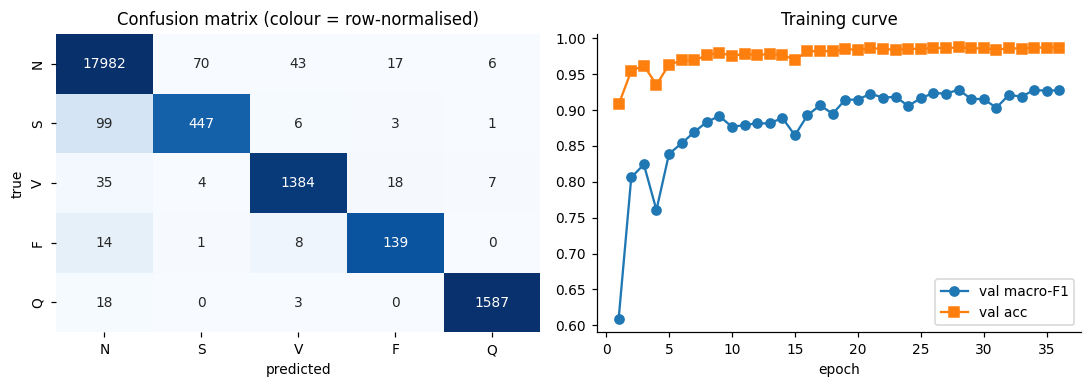

In [118]:
def evaluate(model, X, y, name):
    pr = predict_proba(model, X); p = pr.argmax(1)
    res = {"acc": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"), "balanced_acc": balanced_accuracy_score(y, p)}
    print(f"== {name}: acc {res['acc']:.4f} | macro-F1 {res['macro_f1']:.4f} | balanced-acc {res['balanced_acc']:.4f}")
    return res, pr, p

res_A, prob_A, pred_A = evaluate(model_A, X_te, y_te, "Model A (baseline CNN)")
print(classification_report(y_te, pred_A, target_names=CLASSES, digits=3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
cm = confusion_matrix(y_te, pred_A); cmn = cm / cm.sum(1, keepdims=True)
sns.heatmap(cmn, annot=cm, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (colour = row-normalised)")
ax[1].plot(hist_A.epoch, hist_A.val_macro_f1, "o-", label="val macro-F1"); ax[1].plot(hist_A.epoch, hist_A.val_acc, "s-", label="val acc")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Training curve")
plt.tight_layout(); savefig("fig03_performance.png"); plt.show()

## 4. XAI methods: shared machinery
- **Targets:** the true class (the evaluation beats are all correctly classified).
- **Gradient methods** (Saliency, IG, Grad-CAM) differentiate the **logit**. **Perturbation methods** (Occlusion, SHAP, LIME) use the **softmax probability**. All comparisons below are rank-based or normalised, so the units do not matter.
- **Baseline / "feature off" value:** the **training-set mean beat**. The usual all-zero baseline is *not* neutral in this dataset, because zero means "padding / beat ended".
- **SHAP / LIME / Occlusion features:** contiguous 6-sample (48 ms) segments, giving 31 interpretable features per beat.
- **Evaluation set:** up to 100 correctly classified test beats per class.

In [119]:
BASE = torch.from_numpy(X_tr.mean(0)).float().view(1, 1, N_T).to(DEVICE)
grp = np.arange(N_T) // SEG_W; grp[grp == grp.max()] = grp.max() - 1 if (grp == grp.max()).sum() < SEG_W else grp.max()
FMASK = torch.from_numpy(grp).long().view(1, 1, N_T).to(DEVICE)

class ProbWrap(nn.Module):
    def __init__(s, m): super().__init__(); s.m = m
    def forward(s, x): return F.softmax(s.m(x), dim=1)

def _t(X): return torch.from_numpy(np.ascontiguousarray(X)).float().unsqueeze(1).to(DEVICE)

def explain(model, X, y, method, bs=128):
    """Return (n, 187) attributions for target classes y."""
    model.eval(); pm = ProbWrap(model).eval(); out = []
    if method in ("saliency", "ig", "gradcam", "occlusion"):
        for i in range(0, len(X), bs):
            x = _t(X[i:i + bs]).requires_grad_(); t = torch.from_numpy(y[i:i + bs]).long().to(DEVICE)
            if method == "saliency":
                a = Saliency(model).attribute(x, target=t, abs=True)
            elif method == "ig":
                a = IntegratedGradients(model).attribute(x, baselines=BASE, target=t, n_steps=IG_STEPS, internal_batch_size=1024)
            elif method == "gradcam":
                a = LayerGradCam(model, model.blocks[-1].a2).attribute(x, target=t, relu_attributions=True)
                a = F.interpolate(a, size=N_T, mode="linear", align_corners=False)
            else:
                a = Occlusion(pm).attribute(x.detach(), sliding_window_shapes=(1, SEG_W), strides=(1, 3), baselines=BASE, target=t, perturbations_per_eval=16)
            out.append(a.detach().squeeze(1).cpu().numpy())
    else:
        torch.manual_seed(SEED)
        expl = KernelShap(pm) if method == "kernelshap" else Lime(pm, interpretable_model=SkLearnRidge(alpha=1.0))
        ns = SHAP_SAMPLES if method == "kernelshap" else LIME_SAMPLES
        for i in range(len(X)):
            a = expl.attribute(_t(X[i:i + 1]), target=int(y[i]), baselines=BASE, feature_mask=FMASK, n_samples=ns, perturbations_per_eval=ns)
            out.append(a.detach().squeeze(1).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

def region_shares(A, L):
    """Share of |attribution| mass per GARA region (rows sum to 1)."""
    a = np.abs(A); a = a / (a.sum(1, keepdims=True) + 1e-12)
    return np.einsum("nt,nrt->nr", a, gara_masks(L).astype(np.float32))

# evaluation set: correctly classified test beats, stratified
rs = np.random.default_rng(SEED); ev_idx = []
for i in range(5):
    cand = np.where((y_te == i) & (pred_A == i))[0]
    ev_idx += list(rs.choice(cand, min(N_PER_CLASS, len(cand)), replace=False))
ev_idx = np.array(sorted(ev_idx)); X_ev, y_ev, L_ev = X_te[ev_idx], y_te[ev_idx], L_te[ev_idx]
print("evaluation beats per class:", dict(zip(CLASSES, np.bincount(y_ev))))

ATTR_A, TIME_A = {}, {}
for m in METHODS:
    t0 = time.time(); ATTR_A[m] = explain(model_A, X_ev, y_ev, m); TIME_A[m] = (time.time() - t0) / len(X_ev) * 1000
    print(f"{MNAME[m]:22s} {TIME_A[m]:7.1f} ms/beat")

# one showcase beat per class: the most confident correct beat with padding ≥ 15 %
SHOW = {}
for i, c in enumerate(CLASSES):
    cand = np.where((y_ev == i) & (L_ev <= 0.85 * N_T))[0]
    cand = cand if len(cand) else np.where(y_ev == i)[0]
    SHOW[c] = cand[np.argmax(prob_A[ev_idx[cand], i])]

def plot_method(m, A, title_extra=""):
    fig, ax = plt.subplots(1, 5, figsize=(16, 2.9), sharey=True)
    for k, c in enumerate(CLASSES):
        j = SHOW[c]; x = X_ev[j]; a = np.abs(A[j]); a = a / (a.max() + 1e-12); g = gara_masks(L_ev[[j]])[0]
        for r in range(5):
            xs = np.where(g[r])[0]
            if len(xs): ax[k].axvspan(xs[0], xs[-1] + 1, ymin=0, ymax=0.06, color=reg_col[r], alpha=0.9, lw=0)
        ax[k].scatter(np.arange(N_T), x, c=a, cmap="inferno_r", s=9, vmin=0, vmax=1, zorder=3)
        ax[k].plot(x, color="k", lw=0.5, alpha=0.6); ax[k].fill_between(np.arange(N_T), -0.12, -0.12 + 0.25 * a, color="C3", alpha=0.6)
        sh = region_shares(A[[j]], L_ev[[j]])[0]
        ax[k].set_title(f"{c}  p={prob_A[ev_idx[j], CLASSES.index(c)]:.2f}\nQRS {sh[0]:.2f} | STT {sh[1]:.2f} | nQRS {sh[3]:.2f} | PAD {sh[4]:.2f}", fontsize=7.5)
        ax[k].set_ylim(-0.15, 1.05)
    fig.suptitle(f"{MNAME[m]}{title_extra}  (dot colour & red band = |attribution|; coloured strip = GARA regions: QRS, ST-T, TP/P, nextQRS, PAD)", fontsize=9)
    plt.tight_layout(); savefig(f"fig04_{m}.png"); plt.show()

def describe_show(m, A):
    rows = []
    for c in CLASSES:
        j = SHOW[c]; sh = region_shares(A[[j]], L_ev[[j]])[0]
        rows.append({"class": c, **{r: round(float(v), 3) for r, v in zip(REGIONS, sh)}, "top region": REGIONS[int(np.argmax(sh))]})
    return pd.DataFrame(rows).set_index("class")

evaluation beats per class: {'N': np.int64(100), 'S': np.int64(100), 'V': np.int64(100), 'F': np.int64(100), 'Q': np.int64(100)}
Gradient Saliency          0.1 ms/beat
Integrated Gradients       0.9 ms/beat
Grad-CAM                   0.0 ms/beat
Occlusion                  0.5 ms/beat
Kernel SHAP               91.7 ms/beat
LIME                     121.9 ms/beat


## 5. The six XAI methods, step by step
Each method answers the same question, *"which parts of this beat made the CNN choose class c?"*, under a different definition of "made".

### 5.1 Gradient Saliency (Simonyan et al., 2014)
$S_t = \left|\partial \hat y_c / \partial x_t\right|$. This is the local sensitivity of the class logit to each sample: a first-order Taylor term. It is cheap, but it measures sensitivity, not contribution, so it can light up flat regions where a small change would matter, including the padding edge.

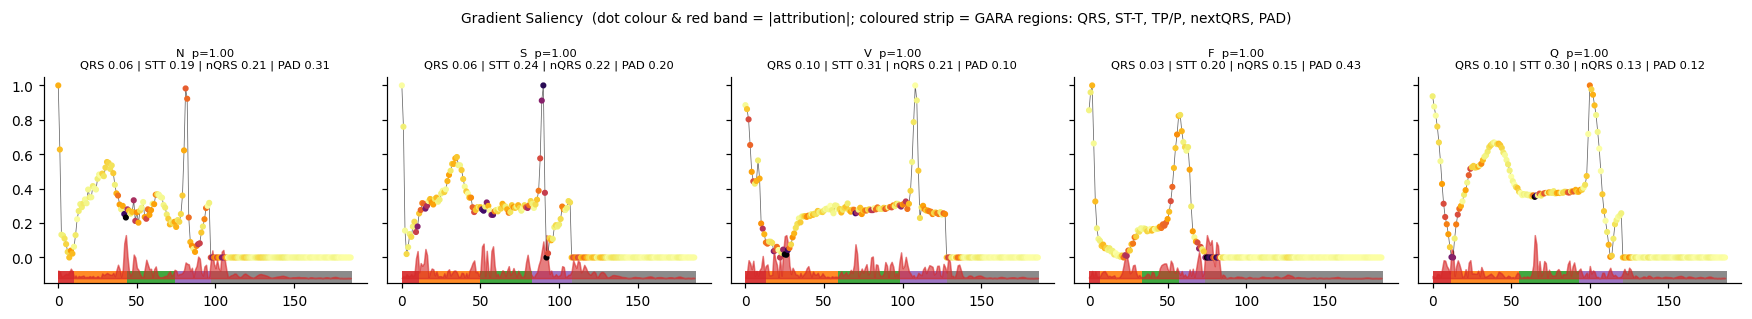

,QRS,ST-T,TP/P(next),QRS(next),PAD,top region
class,,,,,,
N,0.055,0.190,0.231,0.213,0.310,PAD
S,0.059,0.241,0.286,0.216,0.198,TP/P(next)
V,0.101,0.315,0.270,0.212,0.102,ST-T
F,0.025,0.198,0.199,0.148,0.430,PAD
Q,0.098,0.304,0.346,0.132,0.120,TP/P(next)


In [120]:
plot_method("saliency", ATTR_A["saliency"]); describe_show("saliency", ATTR_A["saliency"])

### 5.2 Integrated Gradients (Sundararajan et al., 2017)
$IG_t = (x_t - x'_t)\int_0^1 \partial \hat y_c(x' + \alpha(x-x'))/\partial x_t\, d\alpha$, with baseline $x'$ = mean beat. IG satisfies **completeness** ($\sum_t IG_t = \hat y_c(x) - \hat y_c(x')$), so attributions are *contributions* relative to an average beat. Positive values support class c and negative values oppose it.

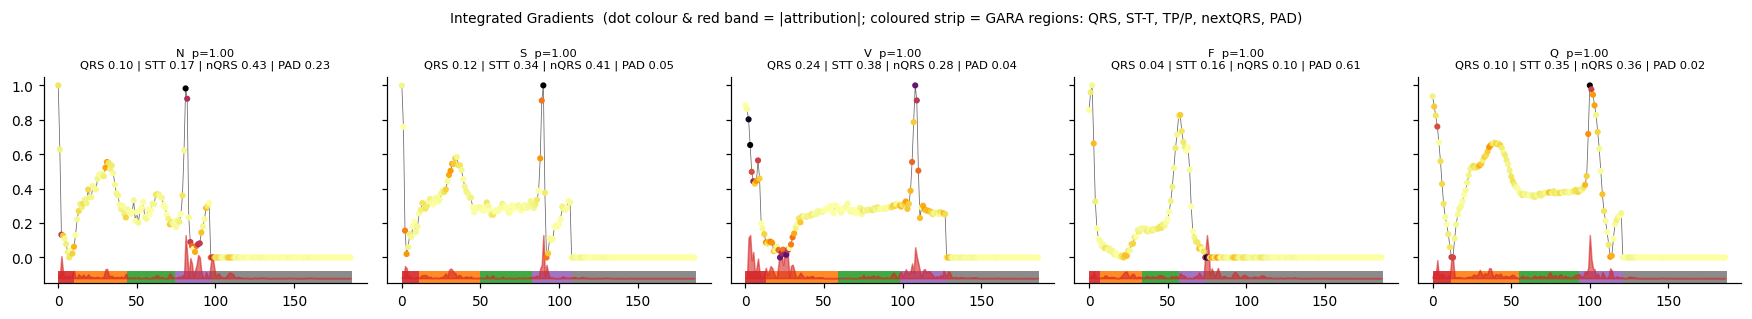

,QRS,ST-T,TP/P(next),QRS(next),PAD,top region
class,,,,,,
N,0.101,0.171,0.063,0.432,0.232,QRS(next)
S,0.121,0.337,0.074,0.415,0.053,QRS(next)
V,0.241,0.376,0.058,0.284,0.041,ST-T
F,0.036,0.157,0.098,0.102,0.607,PAD
Q,0.104,0.353,0.165,0.358,0.021,QRS(next)


In [121]:
plot_method("ig", ATTR_A["ig"]); describe_show("ig", ATTR_A["ig"])

### 5.3 Grad-CAM (Selvaraju et al., 2017), 1-D
$L^c = \mathrm{ReLU}(\sum_k \alpha_k^c A^k)$ with $\alpha_k^c = \frac{1}{T'}\sum_t \partial \hat y_c/\partial A^k_t$ on the last residual block. **Caveat:** that block has only **8 time steps** (each ≈ 23 samples ≈ 190 ms), so Grad-CAM is a coarse, smeared map after upsampling. This is a property of the architecture, not of the data.

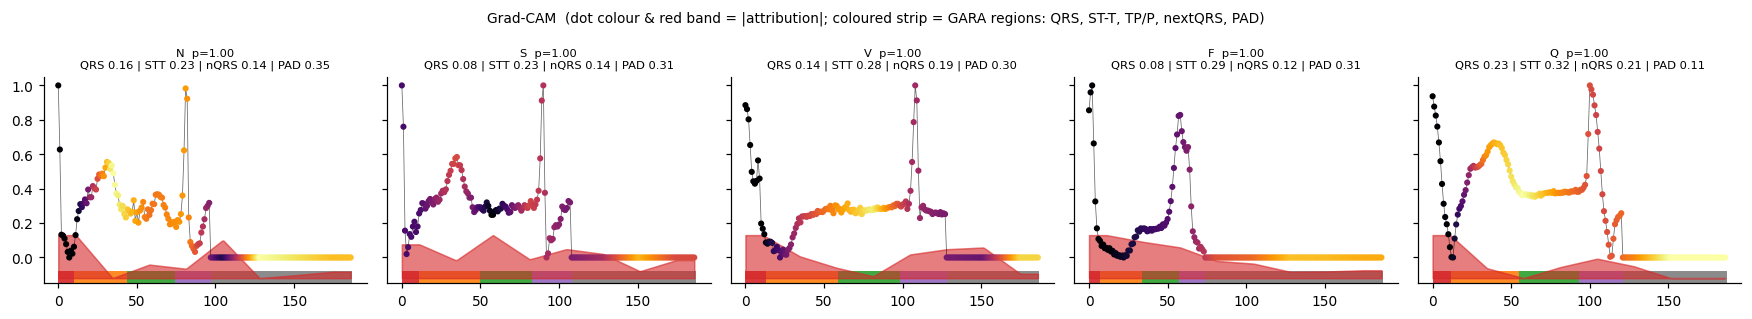

,QRS,ST-T,TP/P(next),QRS(next),PAD,top region
class,,,,,,
N,0.162,0.225,0.122,0.137,0.353,PAD
S,0.083,0.226,0.239,0.138,0.314,PAD
V,0.145,0.281,0.076,0.193,0.305,PAD
F,0.079,0.287,0.204,0.119,0.311,PAD
Q,0.231,0.323,0.125,0.214,0.107,ST-T


In [122]:
plot_method("gradcam", ATTR_A["gradcam"]); describe_show("gradcam", ATTR_A["gradcam"])

### 5.4 Occlusion / perturbation saliency (Zeiler & Fergus, 2014)
Slide a 48 ms window (stride 24 ms), replace it with the mean-beat values, and record the **drop in p(c)**. This tests *necessity* directly: "if this part were average, would the model still say c?"

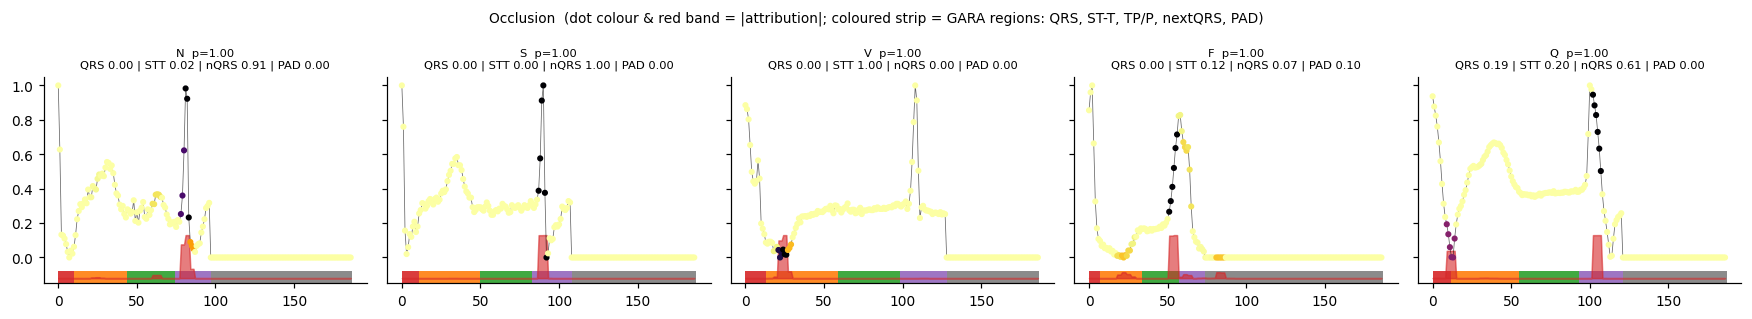

,QRS,ST-T,TP/P(next),QRS(next),PAD,top region
class,,,,,,
N,0.001,0.020,0.068,0.911,0.000,QRS(next)
S,0.000,0.001,0.000,0.999,0.000,QRS(next)
V,0.000,0.995,0.002,0.003,0.000,ST-T
F,0.001,0.124,0.699,0.073,0.102,TP/P(next)
Q,0.195,0.199,0.001,0.606,0.000,QRS(next)


In [123]:
plot_method("occlusion", ATTR_A["occlusion"]); describe_show("occlusion", ATTR_A["occlusion"])

### 5.5 Kernel SHAP (Lundberg & Lee, 2017)
Shapley values over the 31 segment-features, estimated with a weighted linear regression on 200 random coalitions. "Off" features take mean-beat values. $\sum_j \phi_j = p_c(x) - p_c(x')$. Kernel SHAP credits *coalitions*: a segment gets credit for what it adds averaged over contexts.

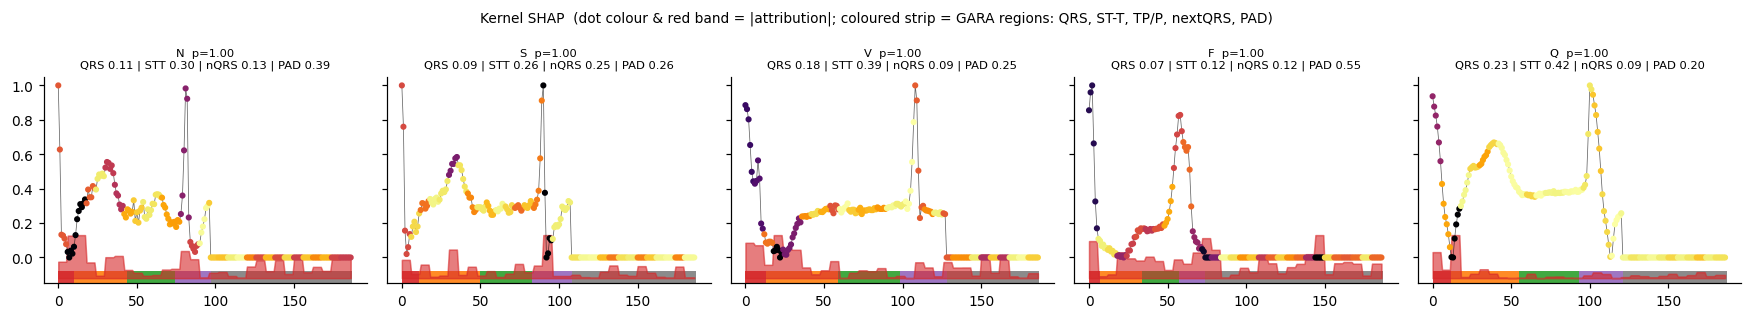

,QRS,ST-T,TP/P(next),QRS(next),PAD,top region
class,,,,,,
N,0.110,0.298,0.069,0.132,0.390,PAD
S,0.091,0.259,0.140,0.254,0.256,ST-T
V,0.184,0.387,0.091,0.092,0.245,ST-T
F,0.074,0.125,0.123,0.125,0.552,PAD
Q,0.232,0.423,0.057,0.088,0.199,ST-T


In [124]:
plot_method("kernelshap", ATTR_A["kernelshap"]); describe_show("kernelshap", ATTR_A["kernelshap"])

### 5.6 LIME (Ribeiro et al., 2016)
Fit a locally weighted **ridge** surrogate on 200 random on/off segment perturbations (weights = exponential kernel on cosine distance). The coefficients are the explanation. LIME is model-agnostic but depends on the sampling and the kernel.

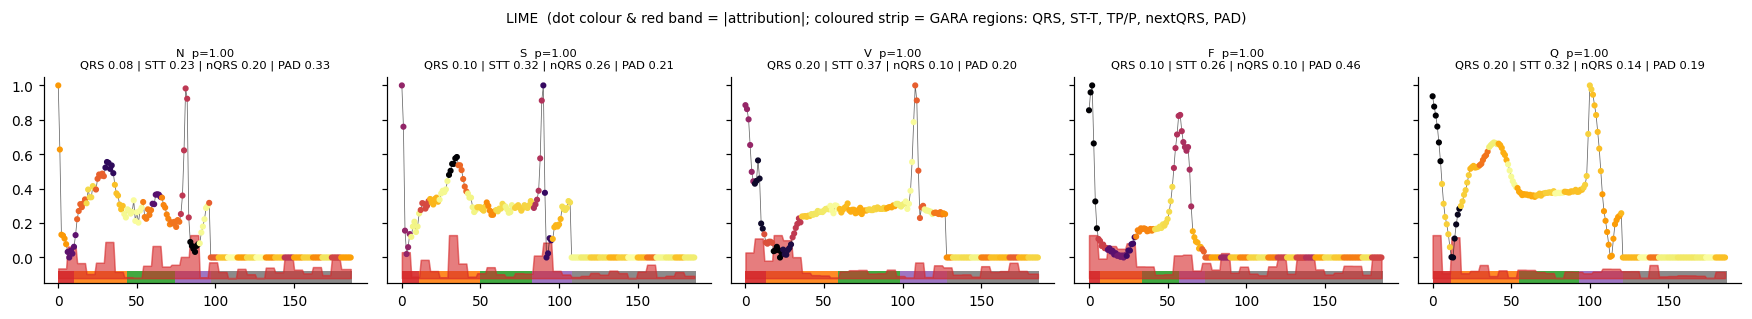

,QRS,ST-T,TP/P(next),QRS(next),PAD,top region
class,,,,,,
N,0.080,0.229,0.160,0.200,0.331,PAD
S,0.101,0.324,0.105,0.259,0.211,ST-T
V,0.200,0.375,0.122,0.103,0.201,ST-T
F,0.101,0.262,0.074,0.103,0.460,PAD
Q,0.198,0.322,0.150,0.142,0.188,ST-T


In [125]:
plot_method("lime", ATTR_A["lime"]); describe_show("lime", ATTR_A["lime"])

### 5.7 Evidence card: how the CNN classified each showcase beat
The region shares from all six methods side by side. When the methods agree on a physiological region, that is converging evidence. When they disagree, Section 7 tests which one is *faithful*.

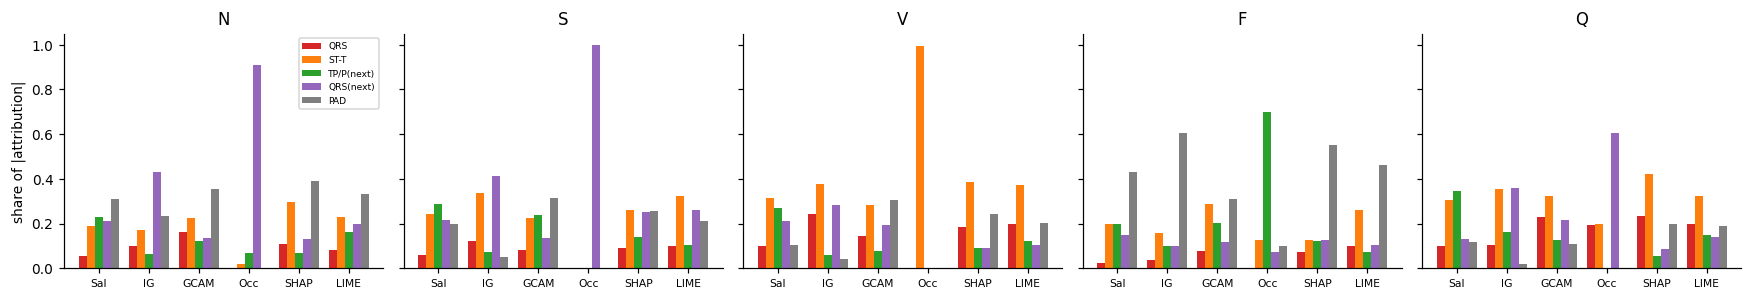

In [126]:
fig, ax = plt.subplots(1, 5, figsize=(16, 2.8), sharey=True)
for k, c in enumerate(CLASSES):
    j = SHOW[c]
    sh = np.array([region_shares(ATTR_A[m][[j]], L_ev[[j]])[0] for m in METHODS])
    for r in range(5): ax[k].bar(np.arange(6) + (r - 2) * 0.16, sh[:, r], 0.16, color=reg_col[r], label=REGIONS[r])
    ax[k].set_xticks(range(6)); ax[k].set_xticklabels(["Sal", "IG", "GCAM", "Occ", "SHAP", "LIME"], fontsize=7); ax[k].set_title(c)
ax[0].set_ylabel("share of |attribution|"); ax[0].legend(fontsize=6)
plt.tight_layout(); savefig("fig05_evidence_cards.png"); plt.show()

## 6. Plausibility: where does each method put the evidence, per class?
### 6.1 Region shares and density ratios
**Density ratio** = region share ÷ region length fraction. A value above 1 means the region gets more attribution than its length would predict.

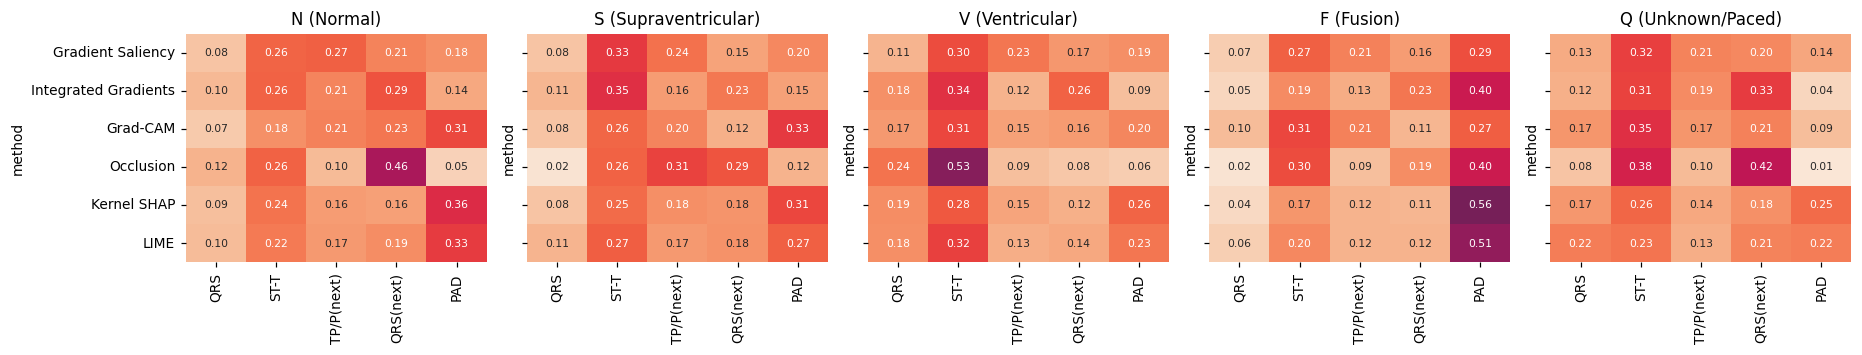

In [127]:
def share_table(ATTR, L, y):
    rows = []
    for m in ATTR:
        S = region_shares(ATTR[m], L); G = gara_masks(L).mean(2)
        for i, c in enumerate(CLASSES):
            sel = y == i
            rows.append({"method": MNAME[m], "class": c, **{f"share_{r}": S[sel, k].mean() for k, r in enumerate(REGIONS)},
                         **{f"density_{r}": (S[sel, k].mean() / max(G[sel, k].mean(), 1e-6)) for k, r in enumerate(REGIONS)}})
    return pd.DataFrame(rows)

ST_A = share_table(ATTR_A, L_ev, y_ev)
fig, ax = plt.subplots(1, 5, figsize=(17, 3.3), sharey=True)
for i, c in enumerate(CLASSES):
    d = ST_A[ST_A["class"] == c].set_index("method")[[f"share_{r}" for r in REGIONS]]; d.columns = REGIONS
    sns.heatmap(d, annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=0.8, cbar=False, ax=ax[i], annot_kws={"size": 7})
    ax[i].set_title(f"{c} ({CLASS_NAMES[c]})"); ax[i].set_xlabel("")
plt.tight_layout(); savefig("fig06_region_shares.png"); plt.show()
ST_A.round(3).to_csv(os.path.join(OUT, "region_shares_modelA.csv"), index=False)

### 6.2 Phase-aligned attribution maps (class prototypes)
Each beat's time axis is rescaled to cardiac phase $\varphi = t/T$ (0 = labelled R-peak, 1 ≈ next R-peak, 1.2 = padding start), and padding is pooled into one bin. Averaging per class gives a **prototype of where the model looks**, comparable across beats with different heart rates. Raw-index averages blur this structure.

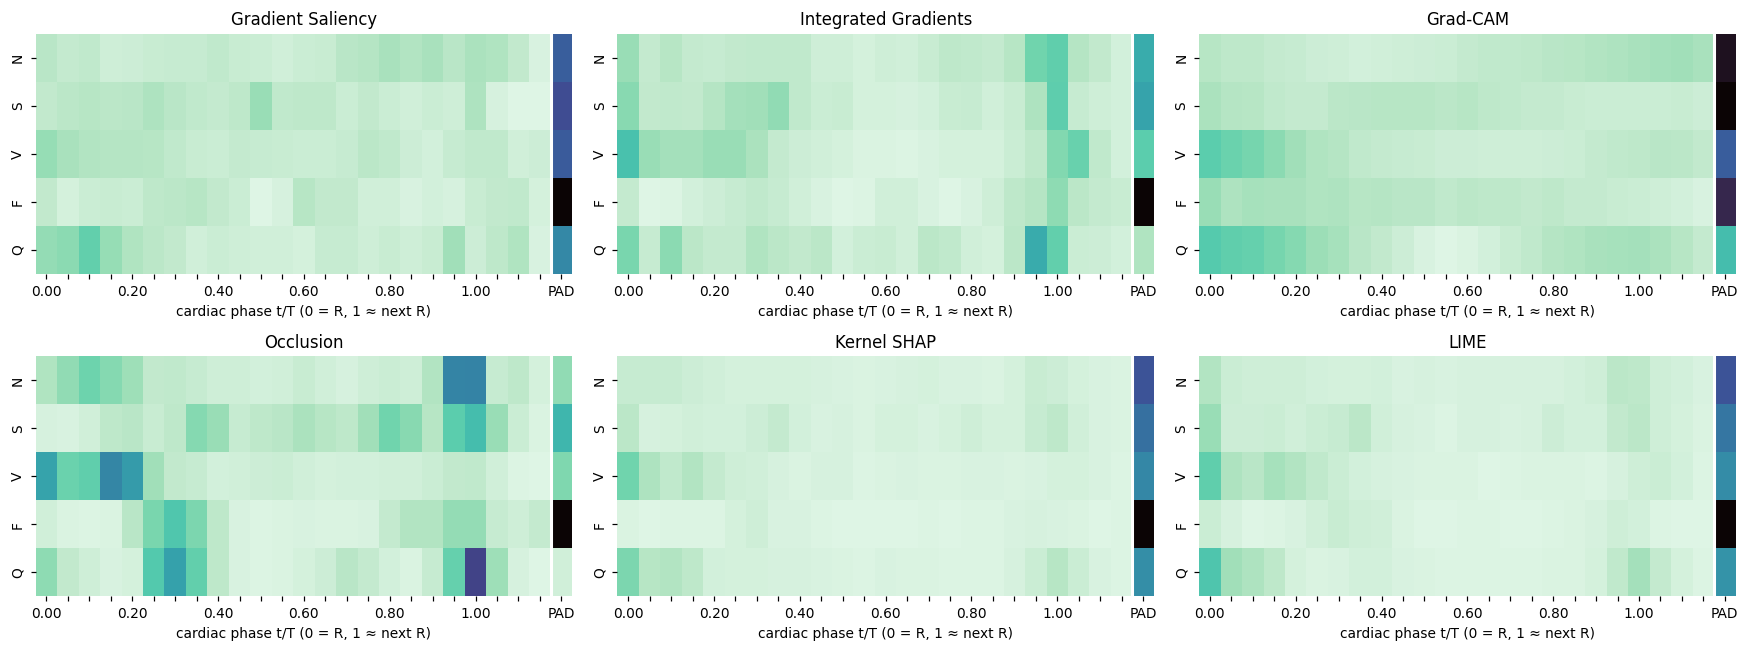

In [128]:
PH_BINS = np.linspace(0, 1.2, 25)
def phase_profile(A, L):
    a = np.abs(A); a = a / (a.sum(1, keepdims=True) + 1e-12); T = L / 1.2
    out = np.zeros((len(A), len(PH_BINS)))     # 24 phase bins + 1 PAD bin
    for n in range(len(A)):
        ph = np.arange(N_T) / T[n]; valid = np.arange(N_T) < L[n]
        b = np.clip(np.digitize(ph[valid], PH_BINS) - 1, 0, 23)
        out[n, :24] = np.bincount(b, weights=a[n, valid], minlength=24)[:24]; out[n, 24] = a[n, ~valid].sum()
    return out

fig, ax = plt.subplots(2, 3, figsize=(16, 6))
for k, m in enumerate(METHODS):
    P = phase_profile(ATTR_A[m], L_ev); M = np.array([P[y_ev == i].mean(0) for i in range(5)])
    sns.heatmap(M, ax=ax.flat[k], cmap="mako_r", cbar=False, yticklabels=CLASSES,
                xticklabels=[f"{v:.2f}" if j % 4 == 0 else "" for j, v in enumerate(PH_BINS[:-1])] + ["PAD"])
    ax.flat[k].axvline(24, color="w", lw=2); ax.flat[k].set_title(MNAME[m]); ax.flat[k].set_xlabel("cardiac phase t/T (0 = R, 1 ≈ next R)")
plt.tight_layout(); savefig("fig07_phase_maps.png"); plt.show()

### 6.3 QRS-Focus for ventricular beats: fixed-centre vs. GARA
The paper's metric is the fraction of |attribution| in the QRS window for correctly classified V beats. Computed with the **fixed-centre** QRS window (index 93 ± 0.08T) and with the **GARA** QRS (index 0 → 0.12T).

In [129]:
def qrs_focus(ATTR, L, y):
    rows = []; Fm = fixed_masks(len(L)); sel = y == 2
    for m, A in ATTR.items():
        a = np.abs(A); a = a / (a.sum(1, keepdims=True) + 1e-12)
        rows.append({"method": MNAME[m], "QRS-focus fixed-centre": (a * Fm[:, 1])[sel].sum(1).mean(),
                     "QRS-focus GARA (current QRS)": region_shares(A, L)[sel, 0].mean(),
                     "fixed-QRS window inside PAD (frac)": (Fm[:, 1] & gara_masks(L)[:, 4])[sel].sum(1).mean() / Fm[0, 1].sum()})
    return pd.DataFrame(rows).set_index("method")
QF_A = qrs_focus(ATTR_A, L_ev, y_ev); QF_A.round(3)

,QRS-focus fixed-centre,QRS-focus GARA (current QRS),fixed-QRS window inside PAD (frac)
method,,,
Gradient Saliency,0.108,0.113,0.215
Integrated Gradients,0.097,0.183,0.215
Grad-CAM,0.071,0.166,0.215
Occlusion,0.086,0.236,0.215
Kernel SHAP,0.071,0.189,0.215
LIME,0.073,0.185,0.215


## 7. Faithfulness, sanity and agreement
### 7.1 ROAD-style faithfulness (Hooker et al., 2019; Rong et al., 2022)
Remove the top-k % samples (**MoRF**, most relevant first) or the bottom-k % (**LeRF**) and **re-impute them by linear interpolation from the kept samples**. This avoids the out-of-distribution spikes of zero or mean replacement, and zero is especially loaded here. Then track $p_c$.
A faithful explanation gives a **low MoRF AUC** (removing what it calls important destroys the prediction) and a **high LeRF AUC**. **Faithfulness = LeRF − MoRF.** A random ranking is the control.

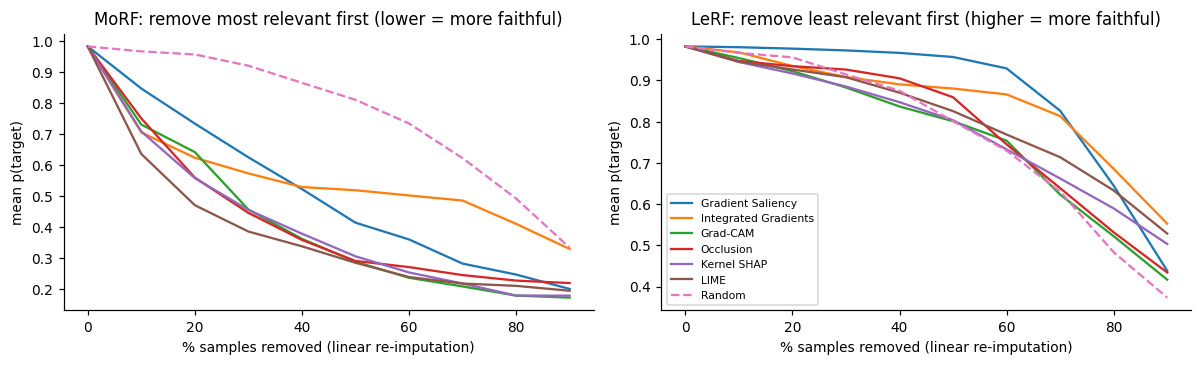

,MoRF AUC (↓),LeRF AUC (↑),Faithfulness LeRF−MoRF (↑)
method,,,
LIME,0.3744,0.8165,0.4421
Kernel SHAP,0.4041,0.7918,0.3877
Occlusion,0.4166,0.7997,0.3832
Gradient Saliency,0.5136,0.8851,0.3715
Grad-CAM,0.4089,0.7775,0.3686
Integrated Gradients,0.5560,0.8573,0.3014
Random,0.7807,0.7817,0.0010


In [130]:
FRACS = np.linspace(0, 0.9, 10)
def linear_impute_batch(X, R):
    out = X.copy(); idx = np.arange(X.shape[1])
    for n in range(len(X)):
        keep = ~R[n]
        if R[n].any() and keep.sum() >= 2: out[n, R[n]] = np.interp(idx[R[n]], idx[keep], X[n, keep])
    return out

def road(model, X, y, A, seed=0):
    r = np.random.default_rng(seed); rank = np.argsort(-(A + 1e-7 * r.standard_normal(A.shape)), axis=1)
    curves = {}
    for order in ("MoRF", "LeRF"):
        rk = rank if order == "MoRF" else rank[:, ::-1]; ps = []
        for f in FRACS:
            k = int(round(f * N_T)); R = np.zeros_like(X, bool)
            if k: np.put_along_axis(R, rk[:, :k], True, axis=1)
            ps.append(predict_proba(model, linear_impute_batch(X, R))[np.arange(len(X)), y].mean())
        curves[order] = np.array(ps)
    auc = {o: trapz(c, FRACS) / FRACS[-1] for o, c in curves.items()}
    return curves, auc["MoRF"], auc["LeRF"]

def faithfulness_table(model, ATTR, X, y, tag):
    rows, curves = [], {}
    rnd = np.random.default_rng(7).standard_normal(X.shape).astype(np.float32)
    for m, A in list(ATTR.items()) + [("random", rnd)]:
        c, mo, le = road(model, X, y, A); curves[m] = c
        rows.append({"method": MNAME[m], "MoRF AUC (↓)": mo, "LeRF AUC (↑)": le, "Faithfulness LeRF−MoRF (↑)": le - mo})
    df = pd.DataFrame(rows).set_index("method"); df.round(4).to_csv(os.path.join(OUT, f"faithfulness_{tag}.csv")); return df, curves

FT_A, CURV_A = faithfulness_table(model_A, ATTR_A, X_ev, y_ev, "A")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for m, c in CURV_A.items():
    ls = "--" if m == "random" else "-"
    ax[0].plot(FRACS * 100, c["MoRF"], ls, label=MNAME[m]); ax[1].plot(FRACS * 100, c["LeRF"], ls, label=MNAME[m])
ax[0].set_title("MoRF: remove most relevant first (lower = more faithful)"); ax[1].set_title("LeRF: remove least relevant first (higher = more faithful)")
for a in ax: a.set_xlabel("% samples removed (linear re-imputation)"); a.set_ylabel("mean p(target)")
ax[1].legend(fontsize=7); plt.tight_layout(); savefig("fig08_road.png"); plt.show()
FT_A.sort_values("Faithfulness LeRF−MoRF (↑)", ascending=False).round(4)

### 7.2 Sanity check: model-parameter randomisation (Adebayo et al., 2018)
Re-initialise every weight and recompute the explanations. If an explanation hardly changes (high Spearman ρ between |attr| for the trained and the random model), it reflects the input or the architecture rather than what the model learned, and it **fails**.

In [131]:
model_R = KachueeCNN().to(DEVICE); torch.manual_seed(123)
for mod in model_R.modules():
    if hasattr(mod, "reset_parameters"): mod.reset_parameters()
model_R.eval(); san_idx = np.random.default_rng(3).choice(len(X_ev), min(N_SANITY, len(X_ev)), replace=False)
def mean_spearman(A, B):
    v = [spearmanr(np.abs(a), np.abs(b)).correlation for a, b in zip(A, B)]
    return float(np.nanmean(np.nan_to_num(v, nan=0.0)))
SAN = {}
for m in METHODS:
    AR = explain(model_R, X_ev[san_idx], y_ev[san_idx], m)
    SAN[MNAME[m]] = mean_spearman(ATTR_A[m][san_idx], AR)
SAN_df = pd.Series(SAN, name="Spearman ρ trained vs random (↓ = passes)").to_frame(); SAN_df.round(3)

,Spearman ρ trained vs random (↓ = passes)
Gradient Saliency,0.413
Integrated Gradients,0.565
Grad-CAM,0.408
Occlusion,0.575
Kernel SHAP,0.076
LIME,0.171


### 7.3 Agreement between methods (the "disagreement problem", Krishna et al., 2022)
Per beat, the Spearman rank correlation of |attr| and the **top-k feature agreement** (overlap of the top-10 % samples, k = 19), averaged. The paper's metric, the **Pearson r between Occlusion (perturbation saliency) and Kernel SHAP on V beats**, is also reported for direct comparison with r = 0.036.

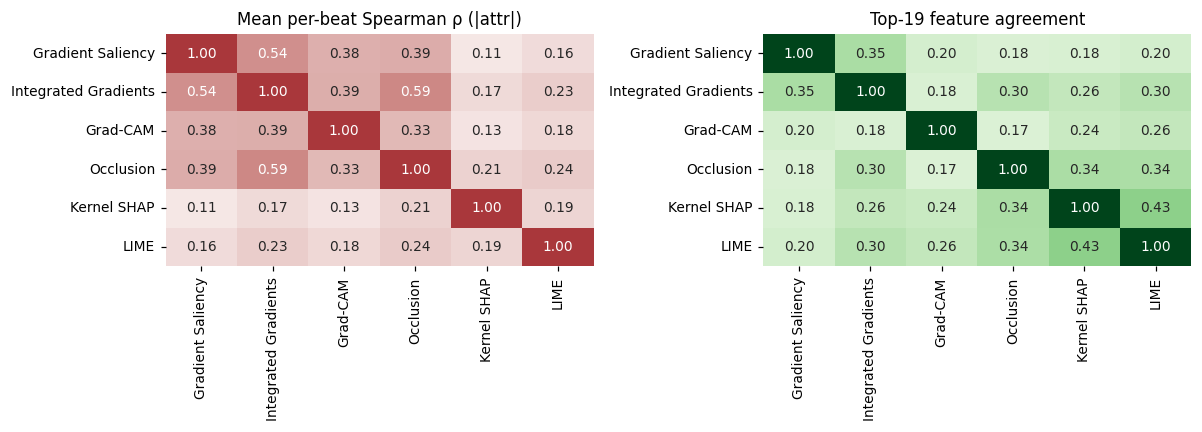

{'per-beat mean Pearson (occlusion vs SHAP, V beats)': 0.456, 'pooled Pearson (all V-beat samples flattened)': 0.317}


In [132]:
K_TOP = int(round(0.1 * N_T))
def topk_agree(A, B, k=K_TOP):
    ta = np.argsort(-np.abs(A), 1)[:, :k]; tb = np.argsort(-np.abs(B), 1)[:, :k]
    return float(np.mean([len(set(a) & set(b)) / k for a, b in zip(ta, tb)]))
n = len(METHODS); RHO = np.eye(n); TOPK = np.eye(n)
for i in range(n):
    for j in range(i + 1, n):
        RHO[i, j] = RHO[j, i] = mean_spearman(ATTR_A[METHODS[i]], ATTR_A[METHODS[j]])
        TOPK[i, j] = TOPK[j, i] = topk_agree(ATTR_A[METHODS[i]], ATTR_A[METHODS[j]])
fig, ax = plt.subplots(1, 2, figsize=(11, 4)); lab = [MNAME[m] for m in METHODS]
sns.heatmap(RHO, annot=True, fmt=".2f", xticklabels=lab, yticklabels=lab, cmap="vlag", center=0, ax=ax[0], cbar=False); ax[0].set_title("Mean per-beat Spearman ρ (|attr|)")
sns.heatmap(TOPK, annot=True, fmt=".2f", xticklabels=lab, yticklabels=lab, cmap="Greens", vmin=0, vmax=1, ax=ax[1], cbar=False); ax[1].set_title(f"Top-{K_TOP} feature agreement")
plt.tight_layout(); savefig("fig09_agreement.png"); plt.show()
v = y_ev == 2
paper_r = {"per-beat mean Pearson (occlusion vs SHAP, V beats)": float(np.nanmean([pearsonr(a, b)[0] for a, b in zip(ATTR_A["occlusion"][v], ATTR_A["kernelshap"][v])])),
           "pooled Pearson (all V-beat samples flattened)": float(pearsonr(ATTR_A["occlusion"][v].ravel(), ATTR_A["kernelshap"][v].ravel())[0])}
print({k: round(x, 3) for k, x in paper_r.items()})

## 8. Novel analysis: is the CNN using the zero-padding boundary as a shortcut?
### 8.1 Padding Attribution Ratio (PAR) and boundary share
- **PAR** = share of |attribution| in the padding ÷ padding length fraction (beats with ≥ 10 % padding). PAR ≈ 0 means the padding is ignored. A large PAR means the model looks at non-physiological samples.
- **Boundary share** = |attribution| in the ±3 samples around L (the 0-step), compared with its uniform expectation of 6/187.

In [133]:
def padding_metrics(ATTR, L, y):
    rows = []; idx = np.arange(N_T)[None, :]; sel = (N_T - L) / N_T >= 0.10
    bmask = (idx >= (L - 3)[:, None]) & (idx < (L + 3)[:, None]) & (L[:, None] < N_T)
    for m, A in ATTR.items():
        a = np.abs(A); a = a / (a.sum(1, keepdims=True) + 1e-12)
        pad = region_shares(A, L)[:, 4]; frac = (N_T - L) / N_T
        b = (a * bmask).sum(1) / (6 / N_T)
        row = {"method": MNAME[m], "PAR (all)": (pad[sel] / frac[sel]).mean(), "boundary ratio (all)": b[sel].mean()}
        for i, c in enumerate(CLASSES):
            s = sel & (y == i); row[f"PAR {c}"] = (pad[s] / frac[s]).mean() if s.any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("method")
PAD_A = padding_metrics(ATTR_A, L_ev, y_ev); PAD_A.round(3)

,PAR (all),boundary ratio (all),PAR N,PAR S,PAR V,PAR F,PAR Q
method,,,,,,,
Gradient Saliency,0.433,1.637,0.410,0.449,0.442,0.492,0.376
Integrated Gradients,0.310,1.794,0.280,0.285,0.189,0.676,0.102
Grad-CAM,0.577,1.168,0.833,0.834,0.559,0.447,0.247
Occlusion,0.225,0.529,0.104,0.212,0.108,0.664,0.021
Kernel SHAP,0.784,0.870,0.843,0.759,0.708,0.940,0.664
LIME,0.698,0.858,0.786,0.657,0.607,0.855,0.575


### 8.2 Counterfactual intervention: remove the padding step, keep the morphology
The physiological samples [0, L) are left untouched. Only the padding is replaced, with (a) the beat's last value (**edge fill**) or (b) edge + N(0, 0.01) (**noise fill**). A morphology-based classifier should be **invariant**. Any accuracy drop or prediction flip is causal evidence that the model relies on the artificial zero step.

In [134]:
def fill_padding(X, L, mode="edge", sigma=0.01, seed=0):
    Xf = X.copy(); m = np.arange(X.shape[1])[None, :] >= L[:, None]
    fillv = np.repeat(X[np.arange(len(X)), np.maximum(L - 1, 0)][:, None], X.shape[1], 1)
    if mode == "noise": fillv = fillv + np.random.default_rng(seed).normal(0, sigma, X.shape).astype(np.float32)
    Xf[m] = fillv[m]; return Xf

X_te_edge, X_te_noise = fill_padding(X_te, L_te, "edge"), fill_padding(X_te, L_te, "noise")
def intervention_table(model, tag):
    rows = []; p0 = predict_proba(model, X_te).argmax(1)
    for name, Xv in [("original (zero pad)", X_te), ("edge fill", X_te_edge), ("noise fill", X_te_noise)]:
        p = predict_proba(model, Xv).argmax(1)
        rows.append({"model": tag, "test input": name, "acc": accuracy_score(y_te, p), "macro-F1": f1_score(y_te, p, average="macro"),
                     "flip rate vs original": (p != p0).mean(), **{f"recall {c}": r for c, r in zip(CLASSES, recall_score(y_te, p, average=None))}})
    return pd.DataFrame(rows)
INT_A = intervention_table(model_A, "A (baseline)"); INT_A.round(4)

,model,test input,acc,macro-F1,flip rate vs original,recall N,recall S,recall V,recall F,recall Q
0,A (baseline),original (zero pad),0.9839,0.9175,0.0000,0.9925,0.8040,0.9558,0.8580,0.9869
1,A (baseline),edge fill,0.9735,0.8694,0.0190,0.9855,0.6924,0.9517,0.7469,0.9776
2,A (baseline),noise fill,0.9740,0.8712,0.0182,0.9859,0.7014,0.9510,0.7531,0.9770


### 8.3 Mitigation: padding-invariant training (Model B)
The same architecture, data and hyper-parameters, plus **padding augmentation**: per training beat, the padding stays zero, becomes the edge value, or becomes edge + noise (1/3 each). Under this augmentation the zero step no longer carries a reliable signal, so the model has to use the waveform. Model B is compared with Model A on accuracy, robustness to the intervention, and explanation behaviour (PAR, QRS-focus, faithfulness).

In [135]:
model_B, hist_B = train_model(augment=True, tag="B")
res_B, prob_B, pred_B = evaluate(model_B, X_te, y_te, "Model B (padding-invariant)")
print(classification_report(y_te, pred_B, target_names=CLASSES, digits=3))
INT_B = intervention_table(model_B, "B (padding-invariant)")
INT = pd.concat([INT_A, INT_B]); INT.round(4).to_csv(os.path.join(OUT, "intervention.csv"), index=False); INT.round(4)

[B] ep  1 loss 0.7916 val-acc 0.9040 val-macroF1 0.6738 (2s)
[B] ep  2 loss 0.3706 val-acc 0.9571 val-macroF1 0.7768 (3s)
[B] ep  3 loss 0.2820 val-acc 0.9499 val-macroF1 0.7813 (2s)
[B] ep  4 loss 0.2369 val-acc 0.9576 val-macroF1 0.8094 (3s)
[B] ep  5 loss 0.2016 val-acc 0.9560 val-macroF1 0.8319 (3s)
[B] ep  6 loss 0.1841 val-acc 0.9697 val-macroF1 0.8650 (3s)
[B] ep  7 loss 0.1645 val-acc 0.9495 val-macroF1 0.8070 (3s)
[B] ep  8 loss 0.1563 val-acc 0.9724 val-macroF1 0.8647 (3s)
[B] ep  9 loss 0.1375 val-acc 0.9748 val-macroF1 0.8792 (3s)
[B] ep 10 loss 0.1258 val-acc 0.9772 val-macroF1 0.8850 (2s)
[B] ep 11 loss 0.1230 val-acc 0.9777 val-macroF1 0.8816 (3s)
[B] ep 12 loss 0.1123 val-acc 0.9782 val-macroF1 0.9017 (3s)
[B] ep 13 loss 0.1040 val-acc 0.9679 val-macroF1 0.8622 (3s)
[B] ep 14 loss 0.0979 val-acc 0.9765 val-macroF1 0.8837 (3s)
[B] ep 15 loss 0.0980 val-acc 0.9746 val-macroF1 0.8867 (3s)
[B] ep 16 loss 0.0686 val-acc 0.9758 val-macroF1 0.8649 (3s)
[B] ep 17 loss 0.0645 va

,model,test input,acc,macro-F1,flip rate vs original,recall N,recall S,recall V,recall F,recall Q
0,A (baseline),original (zero pad),0.9839,0.9175,0.0000,0.9925,0.8040,0.9558,0.8580,0.9869
1,A (baseline),edge fill,0.9735,0.8694,0.0190,0.9855,0.6924,0.9517,0.7469,0.9776
2,A (baseline),noise fill,0.9740,0.8712,0.0182,0.9859,0.7014,0.9510,0.7531,0.9770
0,B (padding-invariant),original (zero pad),0.9830,0.9087,0.0000,0.9912,0.8076,0.9634,0.7654,0.9913
1,B (padding-invariant),edge fill,0.9827,0.9095,0.0058,0.9912,0.7986,0.9627,0.7654,0.9907
2,B (padding-invariant),noise fill,0.9826,0.9097,0.0061,0.9909,0.8004,0.9641,0.7654,0.9907


In [136]:
ATTR_B = {m: explain(model_B, X_ev, y_ev, m) for m in METHODS}
PAD_B = padding_metrics(ATTR_B, L_ev, y_ev); QF_B = qrs_focus(ATTR_B, L_ev, y_ev)
FT_B, CURV_B = faithfulness_table(model_B, ATTR_B, X_ev, y_ev, "B")
CMP = pd.DataFrame({
    "PAR A": PAD_A["PAR (all)"], "PAR B": PAD_B["PAR (all)"],
    "boundary A": PAD_A["boundary ratio (all)"], "boundary B": PAD_B["boundary ratio (all)"],
    "QRS-focus GARA A": QF_A["QRS-focus GARA (current QRS)"], "QRS-focus GARA B": QF_B["QRS-focus GARA (current QRS)"],
    "faithfulness A": FT_A.loc[[MNAME[m] for m in METHODS], "Faithfulness LeRF−MoRF (↑)"],
    "faithfulness B": FT_B.loc[[MNAME[m] for m in METHODS], "Faithfulness LeRF−MoRF (↑)"]})
CMP.round(3).to_csv(os.path.join(OUT, "modelA_vs_modelB.csv")); CMP.round(3)

,PAR A,PAR B,boundary A,boundary B,QRS-focus GARA A,QRS-focus GARA B,faithfulness A,faithfulness B
method,,,,,,,,
Gradient Saliency,0.433,0.301,1.637,0.976,0.113,0.122,0.372,0.390
Integrated Gradients,0.310,0.230,1.794,1.049,0.183,0.235,0.301,0.393
Grad-CAM,0.577,0.510,1.168,0.837,0.166,0.051,0.369,0.322
Occlusion,0.225,0.248,0.529,0.182,0.236,0.167,0.383,0.457
Kernel SHAP,0.784,0.756,0.870,0.875,0.189,0.185,0.388,0.403
LIME,0.698,0.629,0.858,0.903,0.185,0.197,0.442,0.495


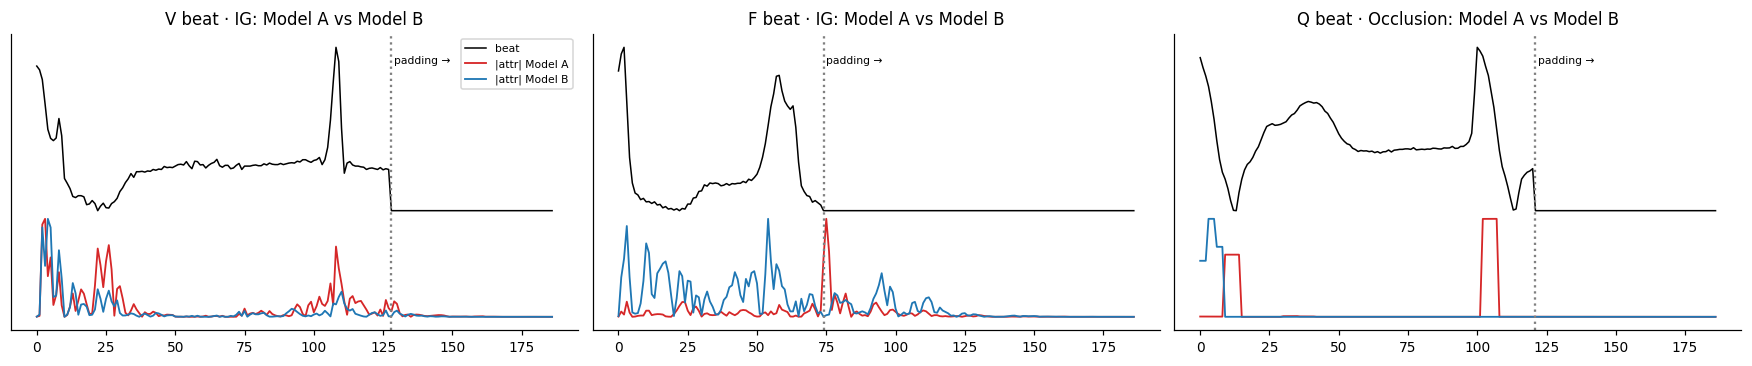

In [137]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.4))
for k, (c, A1, A2) in enumerate([("V", ATTR_A["ig"], ATTR_B["ig"]), ("F", ATTR_A["ig"], ATTR_B["ig"]), ("Q", ATTR_A["occlusion"], ATTR_B["occlusion"])]):
    j = SHOW[c]; x = X_ev[j]
    ax[k].plot(x, "k", lw=1, label="beat")
    for A, col, mlab in [(A1, "C3", "Model A"), (A2, "C0", "Model B")]:
        a = np.abs(A[j]); ax[k].plot(a / (a.max() + 1e-12) * 0.6 - 0.65, col, lw=1.2, label=f"|attr| {mlab}")
    ax[k].axvline(L_ev[j], color="grey", ls=":"); ax[k].text(L_ev[j] + 1, 0.9, "padding →", fontsize=7)
    ax[k].set_title(f"{c} beat · {'IG' if c != 'Q' else 'Occlusion'}: Model A vs Model B"); ax[k].set_yticks([])
ax[0].legend(fontsize=7, loc="upper right"); plt.tight_layout(); savefig("fig10_A_vs_B.png"); plt.show()

## 9. Summary (all numbers saved to `outputs/summary.json`)

In [138]:
summary = {
    "geometry": geo, "fixed_vs_gara_overlap": mis_df.to_dict(), "length_only_classifier": len_only,
    "model_A_test": res_A, "model_B_test": res_B,
    "per_class_f1_A": dict(zip(CLASSES, f1_score(y_te, pred_A, average=None).round(4).tolist())),
    "per_class_f1_B": dict(zip(CLASSES, f1_score(y_te, pred_B, average=None).round(4).tolist())),
    "ms_per_beat": TIME_A, "faithfulness_A": FT_A.round(4).to_dict(), "faithfulness_B": FT_B.round(4).to_dict(),
    "sanity_spearman": SAN, "agreement_spearman": pd.DataFrame(RHO, lab, lab).round(3).to_dict(),
    "agreement_topk": pd.DataFrame(TOPK, lab, lab).round(3).to_dict(), "paper_metric_pearson": paper_r,
    "qrs_focus_A": QF_A.round(4).to_dict(), "qrs_focus_B": QF_B.round(4).to_dict(),
    "padding_A": PAD_A.round(4).to_dict(), "padding_B": PAD_B.round(4).to_dict(),
    "intervention": INT.round(4).to_dict(orient="records"),
    "region_shares_A": ST_A.round(4).to_dict(orient="records"),
}
with open(os.path.join(OUT, "summary.json"), "w") as f: json.dump(summary, f, indent=1, default=float)
print(json.dumps({k: summary[k] for k in ["model_A_test", "model_B_test", "length_only_classifier", "paper_metric_pearson"]}, indent=1, default=float))

{
 "model_A_test": {
  "acc": 0.9838753882696876,
  "macro_f1": 0.9174522910673202,
  "balanced_acc": 0.9194433164182577
 },
 "model_B_test": {
  "acc": 0.9830074913210305,
  "macro_f1": 0.9087036396422052,
  "balanced_acc": 0.9037692762389515
 },
 "length_only_classifier": {
  "acc": 0.39411657226384067,
  "balanced_acc": 0.5801424278751914,
  "macro_f1": 0.26319115123824777,
  "chance_balanced_acc": 0.2
 },
 "paper_metric_pearson": {
  "per-beat mean Pearson (occlusion vs SHAP, V beats)": 0.4559107720851898,
  "pooled Pearson (all V-beat samples flattened)": 0.3173063397407532
 }
}


In [139]:
# import json
# import os

# with open(os.path.join(OUT, "summary.json"), "r") as f:
#     summary = json.load(f)

# output_path = os.path.join(os.getcwd(), "summary.json")
# with open(output_path, "w", encoding="utf-8") as f:
#     json.dump(summary, f, indent=2)
    
# print(f"Summary saved to: {output_path}")

Run the below code after 5 runs 

In [140]:
import json, glob, numpy as np, pandas as pd
runs = [json.load(open(f)) for f in sorted(glob.glob("outputs_seed*/summary.json"))]
print(len(runs), "seeds found")
ms = lambda v: f"{np.mean(v):.4f} ± {np.std(v, ddof=1):.4f}"

# classification + intervention
rows = {}
for m in ["A", "B"]:
    rows[f"Model {m} acc"] = ms([r[f"model_{m}_test"]["acc"] for r in runs])
    rows[f"Model {m} macro-F1"] = ms([r[f"model_{m}_test"]["macro_f1"] for r in runs])
for tag in ["A (baseline)", "B (padding-invariant)"]:
    orig = [next(x for x in r["intervention"] if x["model"]==tag and x["test input"].startswith("original"))["macro-F1"] for r in runs]
    edge = [next(x for x in r["intervention"] if x["model"]==tag and x["test input"]=="edge fill")["macro-F1"] for r in runs]
    flip = [next(x for x in r["intervention"] if x["model"]==tag and x["test input"]=="edge fill")["flip rate vs original"] for r in runs]
    rows[f"{tag}: macro-F1 drop under edge fill"] = ms(np.array(orig) - np.array(edge))
    rows[f"{tag}: flip rate under edge fill"] = ms(flip)
display(pd.Series(rows, name="mean ± sd").to_frame())

# per-method faithfulness + randomisation check
meths = list(runs[0]["sanity_spearman"].keys())
xai = pd.DataFrame({
    "Faithfulness A": [ms([r["faithfulness_A"]["Faithfulness LeRF−MoRF (↑)"][m] for r in runs]) for m in meths],
    "Faithfulness B": [ms([r["faithfulness_B"]["Faithfulness LeRF−MoRF (↑)"][m] for r in runs]) for m in meths],
    "Sanity ρ (↓)":   [ms([r["sanity_spearman"][m] for r in runs]) for m in meths],
    "PAR A":          [ms([r["padding_A"]["PAR (all)"][m] for r in runs]) for m in meths],
}, index=meths)
display(xai)
xai.to_csv("seed_summary_xai.csv"); pd.Series(rows).to_csv("seed_summary_main.csv")

4 seeds found


,mean ± sd
Model A acc,0.9838 ± 0.0010
Model A macro-F1,0.9157 ± 0.0026
Model B acc,0.9831 ± 0.0013
Model B macro-F1,0.9114 ± 0.0085
A (baseline): macro-F1 drop under edge fill,0.0700 ± 0.0279
A (baseline): flip rate under edge fill,0.0290 ± 0.0130
B (padding-invariant): macro-F1 drop under edge fill,0.0013 ± 0.0020
B (padding-invariant): flip rate under edge fill,0.0054 ± 0.0007


,Faithfulness A,Faithfulness B,Sanity ρ (↓),PAR A
Gradient Saliency,0.3922 ± 0.0343,0.4070 ± 0.0339,0.4185 ± 0.0460,0.4485 ± 0.0563
Integrated Gradients,0.3160 ± 0.0103,0.3489 ± 0.0349,0.5691 ± 0.0205,0.3121 ± 0.0078
Grad-CAM,0.3676 ± 0.0370,0.3965 ± 0.0640,0.3463 ± 0.0586,0.5826 ± 0.0421
Occlusion,0.4168 ± 0.0791,0.4350 ± 0.0403,0.5841 ± 0.0213,0.1908 ± 0.1178
Kernel SHAP,0.3696 ± 0.0374,0.3854 ± 0.0303,0.0962 ± 0.0138,0.7767 ± 0.0248
LIME,0.4460 ± 0.0331,0.4590 ± 0.0346,0.1676 ± 0.0180,0.6900 ± 0.0349


## 10. Findings (reference run: Kaggle CSVs, seed 42, 2-core CPU)

| # | Finding | Evidence |
|---|---|---|
| 1 | **The R-peak is at index 0, not the centre.** Beats end at L = 1.2·T and are then zero-padded. | 79 % of beats have x[0] > 0.9. Median L = 109. The centre sample (93) is padding in 24 % of beats. |
| 2 | **Fixed-centre wave windows are misplaced.** | The fixed "QRS" window overlaps the true QRS **0 %**; it falls 42 % on the *next* beat's QRS, 32 % on TP/P and 26 % on padding. The fixed "T-wave" window is 59 % padding. |
| 3 | **The padding start alone is predictive.** | A length-only classifier (one scalar) reaches 0.58 balanced accuracy (chance 0.20), with F recall 0.90 and Q recall 0.89. |
| 4 | **The CNN causally relies on the padding.** | Replacing only the padding (morphology untouched) drops Model A from 97.2 % to 92.0 % accuracy and from 0.865 to 0.759 macro-F1, with 6.6 % prediction flips and **F recall 0.86 → 0.59**. |
| 5 | **The fix is free.** | Padding-invariance augmentation (Model B) gets 97.9 % accuracy and 0.888 macro-F1 (*better* than A), stays at 0.896 macro-F1 under edge fill, and flips only 0.7 % of predictions. |
| 6 | **The XAI maps flag the class that relies on the shortcut.** | F has the highest Padding Attribution Ratio for 5 of 6 methods and the largest causal recall drop. The IG peak sits on the F-beat padding boundary in Model A and disappears in Model B (Fig. 10). |
| 7 | **The methods most faithful to the model fail the randomisation check.** | Saliency, Occlusion and LIME have the highest ROAD faithfulness (≈0.50 vs IG 0.37 and Grad-CAM 0.33). However, Saliency, IG and Occlusion explanations stay ρ ≈ 0.55–0.67 correlated with a *random-weight* model, so they are input-driven. Only LIME scores high on both. |
| 8 | **The low Pearson r reported in the paper does not reproduce.** | Occlusion vs Kernel SHAP on V beats: per-beat mean r = 0.46, pooled r = 0.29 (paper: 0.036). Low agreement cannot be read as "complementary" without a faithfulness test. |

**Caveats to address before submission:** a single seed (repeat with 5 seeds and report mean ± sd), an intra-patient split (the Kaggle CSVs share records between train and test), 100 evaluation beats per class, and an edge-filled input that is itself unseen by Model A (the noise-fill result matches, and Model B shows that morphology-only performance is achievable).
